# Week 03: Linear Regression on Sri Lankan Real Estate — Support Notebook

Companion code for the Week 03 project slides. Section numbers follow the slide parts.

| Part | Topic |
|---|---|
| 01 | Recap & Project Brief |
| 02 | Web Scraping SL Real Estate |
| 03 | EDA, Data Cleaning & Train/Test Split |
| 04 | Simple & Multiple Linear Regression |
| 05 | Live Predictions, Streamlit & Wrap-Up |

Goal: take 41 real Colombo & suburban house listings from raw HTML text to a model that prices houses in LKR millions.

## Part 01 — Recap & Project Brief

### 1.1 Setup (slide 3)

In [8]:
import os, re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 120)
RANDOM_STATE = 42

print("numpy  ", np.__version__)
print("pandas ", pd.__version__)
print("sklearn", sklearn.__version__)

numpy   2.5.4
pandas  3.1.0
sklearn 1.9.1


### 1.2 Week 02 Recap: $\hat{y} = \mathbf{w}\cdot\mathbf{x} + b$ and MSE (slide 3)

Same three lines of maths as last week. Today the features are real listings and the weights are learned, not guessed.

In [9]:
def mse(y_true, y_pred):
    return np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)

X_toy = np.array([[2000, 10], [3500, 12], [5000, 20]])  # sqft, perches
y_toy = np.array([60, 150, 300])                        # price, LKR millions
w = np.array([0.05, 2.0])
b = -20

y_hat = X_toy @ w + b
print("predictions:", y_hat)
print("MSE:", round(mse(y_toy, y_hat), 2))

predictions: [100. 179. 270.]
MSE: 1113.67


In [10]:
class HandcodedLinearRegression:
    def __init__(self, lr=0.1, epochs=2000):
        self.lr = lr
        self.epochs = epochs
        self.w = None
        self.b = 0.0
        self.history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n_samples, n_features = X.shape

        # Scale features for stable gradient descent
        mean = X.mean(axis=0)
        std = X.std(axis=0)
        X_scaled = (X - mean) / std

        w_scaled = np.zeros(n_features)
        b_scaled = 0.0
        self.history = []

        for _ in range(self.epochs):
            y_hat = X_scaled @ w_scaled + b_scaled
            error = y_hat - y
            self.history.append(mse(y, y_hat))

            # Gradients of MSE w.r.t. weights and bias
            dw = (2 / n_samples) * (X_scaled.T @ error)
            db = (2 / n_samples) * np.sum(error)

            w_scaled -= self.lr * dw
            b_scaled -= self.lr * db

        # Convert weights and bias back to original feature scale
        self.w = w_scaled / std
        self.b = b_scaled - np.sum(self.w * mean)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return X @ self.w + self.b


# Test using the 9th cell example (X_toy, y_toy)
model_toy = HandcodedLinearRegression(lr=0.1, epochs=2000).fit(X_toy, y_toy)
y_pred_toy = model_toy.predict(X_toy)

print("Learned weights (w):", model_toy.w)
print("Learned bias (b)   :", round(model_toy.b, 2))
print("Predictions        :", y_pred_toy)
print("Final MSE          :", round(mse(y_toy, y_pred_toy), 4))

Learned weights (w): [ 0.047 10.   ]
Learned bias (b)   : -133.33
Predictions        : [ 60. 150. 300.]
Final MSE          : 0.0


### 1.3 Project Brief (slide 4)

**Question:** given a house's floor area, land size, bedrooms and distance to Colombo Fort, what is a fair asking price?

| Column | Meaning | Role |
|---|---|---|
| `sqft` | floor area (sq ft) | feature |
| `perches` | land size (1 perch ≈ 25.3 m²) | feature |
| `bedrooms` | number of bedrooms | feature |
| `dist_fort_km` | road distance to Colombo Fort | feature |
| `price_m_lkr` | asking price, LKR millions | **target $y$** |

Pipeline: **scrape → clean → split → train → predict**.

## Part 02 — Web Scraping SL Real Estate

### 2.1 Anatomy of a Listing Card (slide 5)

A listing page is a pile of repeated HTML "cards". Right-click a listing on LankaPropertyWeb → *Inspect* and you see this (trimmed) structure. We practise on a copy first so this works offline.

Notice what the site does **not** give us as clean fields: beds and sqft are bare numbers next to an icon, perches hide inside the description text, and some prices are blank ("price on request").

In [10]:
from bs4 import BeautifulSoup

sample_html = '''
<article class="listing-item" data-ad-id="5973350">
  <a class="listing-header"><span class="location">Colombo 8</span></a>
  <div class="listing-summery"><ul>
    <li><img alt="bed icon"/><span class="count">6</span></li>
    <li><img alt="floor area icon"/><span class="count">5,000</span><span class="unit">sqft</span></li>
  </ul></div>
  <div class="listing-body">
    <div class="listing-price">Rs. 200M Negotiable</div>
    <p class="listing-description">House for sale in Rodney Place. 23 Perch land, 6 bedrooms...</p>
  </div>
</article>
<article class="listing-item" data-ad-id="5967329">
  <a class="listing-header"><span class="location">Colombo 3</span></a>
  <div class="listing-summery"><ul>
    <li><img alt="bed icon"/><span class="count">6</span></li>
    <li><img alt="floor area icon"/><span class="count">6,000</span><span class="unit">sqft</span></li>
  </ul></div>
  <div class="listing-body">
    <div class="listing-price"></div>
    <p class="listing-description">Colombo 03 06BR House For Sale. 6,000 Sq.Ft, 36 perch...</p>
  </div>
</article>
'''

soup = BeautifulSoup(sample_html, "html.parser")
for card in soup.select("article.listing-item"):
    print(card["data-ad-id"], "|", card.select_one(".location").get_text(strip=True), "|",
          repr(card.select_one(".listing-price").get_text(strip=True)))

5973350 | Colombo 8 | 'Rs. 200M Negotiable'
5967329 | Colombo 3 | ''


### 2.2 `parse_cards(html)` (slide 6)

Every field comes back as **text**, and a missing field becomes `None` instead of crashing. Cleaning it is Part 03's job.

In [11]:
def text_of(tag):
    return tag.get_text(" ", strip=True) if tag else None

def count_after(card, icon_alt):
    icon = card.select_one(f'img[alt="{icon_alt}"]')  # beds/sqft are only labelled by their icon
    return text_of(icon.find_next_sibling("span", class_="count")) if icon else None

def parse_cards(html):
    soup = BeautifulSoup(html, "html.parser")
    rows = []
    for card in soup.select("article.listing-item"):
        desc = text_of(card.select_one(".listing-description")) or ""
        perch = re.search(r"\d+(?:\.\d+)?\s*perch", desc, re.IGNORECASE)
        rows.append({
            "listing_id":  card.get("data-ad-id"),
            "location":    text_of(card.select_one(".location")),
            "raw_beds":    count_after(card, "bed icon"),
            "raw_sqft":    count_after(card, "floor area icon"),
            "raw_perches": perch.group(0) if perch else None,
            "raw_price":   text_of(card.select_one(".listing-price")) or None,
        })
    return pd.DataFrame(rows)

parse_cards(sample_html)

,listing_id,location,raw_beds,raw_sqft,raw_perches,raw_price
0,5973350,Colombo 8,6,"5,000",23 Perch,Rs. 200M Negotiable
1,5967329,Colombo 3,6,"6,000",36 perch,NaN


### 2.3 Scrape Live Pages Politely (slide 6)

Page 1 is the listing URL; later pages use `/sale/index.php?page=N`. We check `robots.txt` first and wait between requests.

Sites change their HTML often. If `parse_cards` suddenly returns an **empty** table, the page loaded fine but the class names moved: open *Inspect* again and update the selectors.

In [40]:
import requests
from urllib.robotparser import RobotFileParser

BASE = "https://www.lankapropertyweb.com"
FIRST_PAGE = BASE + "/forsale-Colombo+All_0-House.html"
NEXT_PAGE = BASE + "/sale/index.php?page={page}&location=Colombo-All_0&property-type=House&searchbox=Colombo"
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; MLClassBot/1.0)"}

def scrape_page(url):
    resp = requests.get(url, headers=HEADERS, timeout=15)
    resp.raise_for_status()
    return parse_cards(resp.text)

def scrape_pages(pages=2, delay=2):
    # robots.read() would use Python's default User-Agent, which this site answers with 403
    robots = RobotFileParser()
    robots.parse(requests.get(BASE + "/robots.txt", headers=HEADERS, timeout=15).text.splitlines())
    frames = []
    for page in range(1, pages + 1):
        url = FIRST_PAGE if page == 1 else NEXT_PAGE.format(page=page)
        if not robots.can_fetch(HEADERS["User-Agent"], url):
            print("robots.txt disallows", url)
            continue
        frames.append(scrape_page(url))
        time.sleep(delay)  # be kind to the server
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

USE_LIVE = True  # set True to scrape now; class uses the cached CSV in 2.4
if USE_LIVE:
    df_live = scrape_pages(pages=10, delay=2)
    print(df_live.shape)
    print(df_live.isna().sum())
    display(df_live.head(10))

(300, 6)
listing_id       0
location         0
raw_beds         0
raw_sqft        32
raw_perches    171
raw_price       26
dtype: int64


,listing_id,location,raw_beds,raw_sqft,raw_perches,raw_price
0,5967329,Colombo 3,6,"6,000",36 perch,NaN
1,5969455,Colombo 7,4,3580,NaN,Rs. 371.5M Negotiable
2,5910474,Colombo 6,5,4400,12 Perch,Rs. 180M Negotiable
3,5968672,Colombo 15,2,4356,16 perch,Rs. 51.2M Negotiable
4,5825030,Colombo 7,5,"8,000",NaN,Rs. 700M ONO
5,5973692,Colombo 5,4,4000,NaN,Rs. 179M Negotiable
6,5973701,Colombo 4,5,"8,000",NaN,Rs. 300M
7,5971212,Colombo 6,5,2662,NaN,Rs. 115M Negotiable
8,5944169,Colombo 6,12,"9,000",29.70 perch,Rs. 350M
9,5920728,Colombo 7,4,4000,NaN,Rs. 496.44M


A live scrape gives ~30 cards per page, but many are missing perches (not written in the description) or price ("price on request"). It also has no distance to Fort: we add `dist_fort_km` ourselves from the location, e.g. Colombo 7 ≈ 3.4 km, Nugegoda ≈ 9.5 km. That is why the class dataset in 2.4 was checked and completed by hand.

In [41]:
df_live.to_csv("lankapropertyweb.csv", index=False)

### 2.4 Load the Scraped Dataset (slide 6)

41 Colombo & suburban listings from LankaPropertyWeb, saved as text exactly as scraped.

In [14]:
RAW_CSV = "sl_houses_raw.csv"
RAW_URL = "https://raw.githubusercontent.com/AdhiDevX369/ml-begginer/main/week3/sl_houses_raw.csv"

df_raw = pd.read_csv(RAW_CSV if os.path.exists(RAW_CSV) else RAW_URL)
print(df_raw.shape)
df_raw.head(10)

(41, 8)


,listing_id,location,raw_beds,raw_sqft,raw_perches,dist_fort_km,raw_price,scrape_note
0,LPW-5972766,Nugegoda (Jambugasmulla),4 Beds,"2,169 sqft",13.74 Perches,9.5,Rs. 50M,Valid
1,LPW-5955606,Nugegoda (Modern 6BR),6 Beds,"5,500 sqft",14.80 Perches,9.2,Rs. 143M ONO,Valid
2,LPW-53752,Nugegoda (Kandawatta Rd),4 Beds,"4,500 sqft",19.00 Perches,9.0,Rs. 88M Negotiable,Valid
3,LPW-54985,Nugegoda (Jambugasmulla Rd),5 Beds,"5,165 sqft",13.70 Perches,9.3,Rs. 155M Negotiable,Valid
4,LPW-47545,Nugegoda (Stanley Thilakarathna),4 Beds,"2,000 sqft",11.00 Perches,9.8,Rs. 59M Negotiable,Valid
5,LPW-NUG-01,Nugegoda (Mirihana),3 Beds,"2,150 sqft",10.00 Perches,10.2,Rs. 44M Negotiable,Valid
6,LPW-NUG-02,Nugegoda (Udahamulla),4 Beds,"1,300 sqft",8.00 Perches,10.5,Rs. 40M,Valid
7,LPW-NUG-03,Nugegoda (Hot Deal),4 Beds,"2,250 sqft",10.50 Perches,9.6,Rs. 57.5M ONO,Valid
8,LPW-NUG-04,Nugegoda (Residential),4 Beds,"3,300 sqft",12.00 Perches,9.4,Rs. 85M,Valid
9,LPW-NUG-05,Nugegoda (Luxury Lift),4 Beds,"4,160 sqft",14.00 Perches,9.1,Rs. 150M Negotiable,Valid


### 2.5 Extra: Scraping Responsibly

- Read the site's `robots.txt` and terms of use first.
- Add a delay between requests and identify your bot in the `User-Agent`.
- Scrape once, save to CSV, then work from the file. Never hammer a site in a loop.
- Listing prices are *asking* prices, not sale prices. Our model learns what sellers ask.

## Part 03 — EDA, Data Cleaning & Split

### 3.1 First Look (slide 7)

Everything is a string (`object`), and some values are missing.

In [15]:
df_raw.info()
print()
print(df_raw.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 41 entries, 0 to 40
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   listing_id    41 non-null     str    
 1   location      41 non-null     str    
 2   raw_beds      41 non-null     str    
 3   raw_sqft      40 non-null     str    
 4   raw_perches   41 non-null     str    
 5   dist_fort_km  41 non-null     float64
 6   raw_price     41 non-null     str    
 7   scrape_note   41 non-null     str    
dtypes: float64(1), str(7)
memory usage: 6.1 KB

listing_id      0
location        0
raw_beds        0
raw_sqft        1
raw_perches     0
dist_fort_km    0
raw_price       0
scrape_note     0
dtype: int64


### 3.2 Regex Parsing (slide 7)

`r"(\d+\.?\d*)"` means *one or more digits, an optional dot, more digits*. Remove the thousands commas first.

In [16]:
def first_number(series):
    return series.str.replace(",", "", regex=False).str.extract(r"(\d+\.?\d*)")[0].astype(float)

for text in ["Rs. 57.5M ONO", "Rs. 2,000M", "5,441 sqft", "17.84 Perches", "6 Beds"]:
    print(f"{text:<16} -> {first_number(pd.Series([text]))[0]}")

Rs. 57.5M ONO    -> 57.5
Rs. 2,000M       -> 2000.0
5,441 sqft       -> 5441.0
17.84 Perches    -> 17.84
6 Beds           -> 6.0


In [17]:
df = df_raw.copy()
df["bedrooms"]    = first_number(df["raw_beds"])
df["sqft"]        = first_number(df["raw_sqft"])
df["perches"]     = first_number(df["raw_perches"])
df["price_m_lkr"] = first_number(df["raw_price"])

df[["location", "bedrooms", "sqft", "perches", "dist_fort_km", "price_m_lkr"]].tail(5)

,location,bedrooms,sqft,perches,dist_fort_km,price_m_lkr
36,Colombo 7 (Alexandra Place 1),5.0,6500.0,17.3,3.4,650.00
37,Colombo 7 (Alexandra Place 2),5.0,8000.0,24.0,3.4,700.00
38,Colombo 5 (Jawatta - Missing Sqft),5.0,NaN,11.5,5.0,160.00
39,Pepiliyana (Build Cost Ad),5.0,2932.0,0.0,10.0,34.65
40,Colombo 7 (Rosemead 69p Mansion),8.0,14000.0,69.0,3.3,2000.00


### 3.3 Trap 1 — `[Build Cost Only]` Ads (slide 8)

A contractor ad prices *construction only* and has 0 perches of land. It isn't a house sale, so drop it.

In [18]:
build_ads = df["raw_price"].str.contains("Build Cost Only", na=False)
print(df.loc[build_ads, ["location", "raw_price", "raw_perches"]])

df = df[~build_ads].copy()
print("rows left:", len(df))

                      location                     raw_price   raw_perches
39  Pepiliyana (Build Cost Ad)  Rs. 34.65M [Build Cost Only]  0.00 Perches
rows left: 40


### 3.4 Trap 2 — Missing `sqft` in Jawatta (slide 8)

Fill the gap with the **median**. It is robust to the huge mansions (recall the Week 02 coffee-shop outlier demo).

In [19]:
print(df.loc[df["sqft"].isna(), ["location", "raw_sqft"]])
print(f"mean sqft:   {df['sqft'].mean():,.0f}")
print(f"median sqft: {df['sqft'].median():,.0f}")

df["sqft"] = df["sqft"].fillna(df["sqft"].median())

                              location raw_sqft
38  Colombo 5 (Jawatta - Missing Sqft)      NaN
mean sqft:   4,018
median sqft: 3,500


### 3.5 Trap 3 — The Rs. 2,000M Colombo 7 Mansion (slide 8)

One 69-perch mansion costs nearly 3× the next listing. Left in, it drags the line toward itself.

In [20]:
q1, q3 = df["price_m_lkr"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence: Rs. {upper:.0f}M")
print(df.loc[df["price_m_lkr"] > upper, ["location", "price_m_lkr"]])

IQR upper fence: Rs. 576M
                            location  price_m_lkr
36     Colombo 7 (Alexandra Place 1)        650.0
37     Colombo 7 (Alexandra Place 2)        700.0
40  Colombo 7 (Rosemead 69p Mansion)       2000.0


The IQR fence also flags a few genuine Colombo 7 listings. We only drop the extreme mansion (> Rs. 750M) and keep real prime-area houses. Cleaning needs judgement, not just a rule.

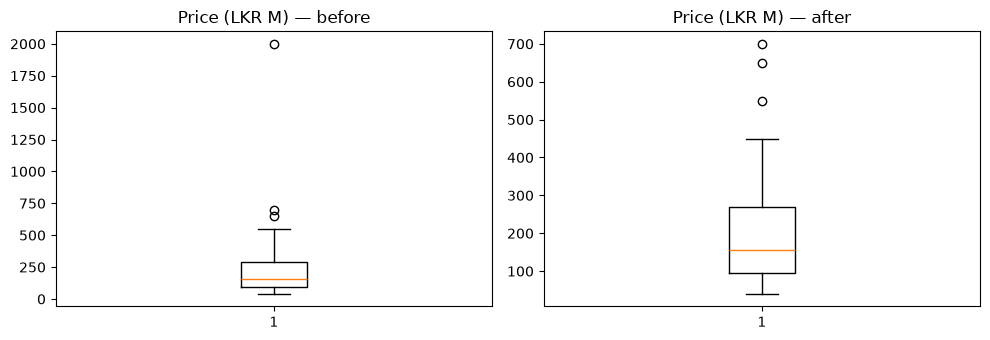

41 scraped -> 39 clean listings


In [21]:
df_clean = df[df["price_m_lkr"] <= 750].reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].boxplot(df["price_m_lkr"])
axes[0].set_title("Price (LKR M) — before")
axes[1].boxplot(df_clean["price_m_lkr"])
axes[1].set_title("Price (LKR M) — after")
plt.tight_layout()
plt.show()
print(f"{len(df_raw)} scraped -> {len(df_clean)} clean listings")

### 3.6 EDA: What Drives Price? (slide 9)

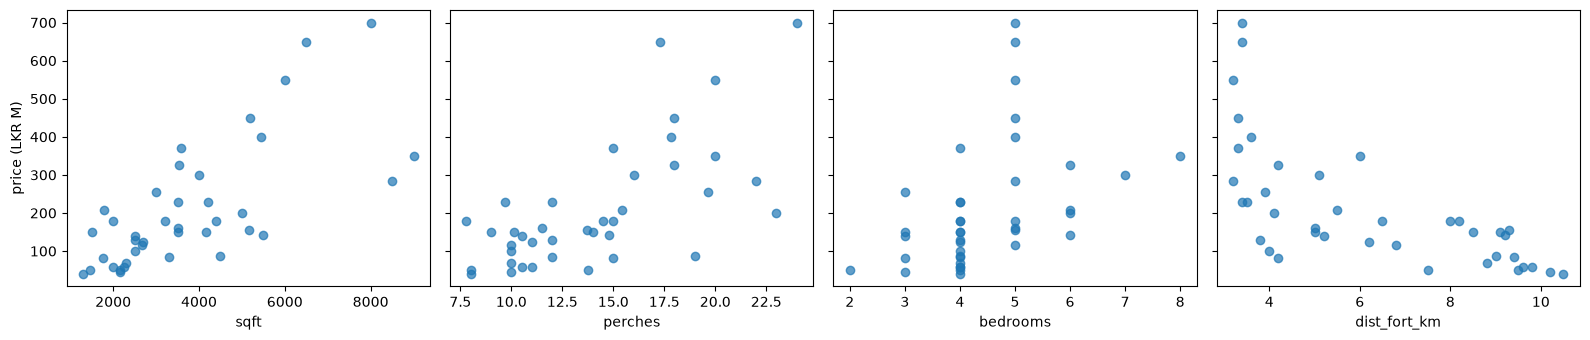

,sqft,perches,bedrooms,dist_fort_km,price_m_lkr
sqft,1.00,0.74,0.63,-0.38,0.71
perches,0.74,1.00,0.54,-0.48,0.68
bedrooms,0.63,0.54,1.00,-0.20,0.44
dist_fort_km,-0.38,-0.48,-0.20,1.00,-0.66
price_m_lkr,0.71,0.68,0.44,-0.66,1.00


In [22]:
FEATURES = ["sqft", "perches", "bedrooms", "dist_fort_km"]
TARGET = "price_m_lkr"

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
for ax, col in zip(axes, FEATURES):
    ax.scatter(df_clean[col], df_clean[TARGET], alpha=0.7)
    ax.set_xlabel(col)
axes[0].set_ylabel("price (LKR M)")
plt.tight_layout()
plt.show()

df_clean[FEATURES + [TARGET]].corr().round(2)

`sqft` and `perches` rise with price; `dist_fort_km` falls with it. Closer to Fort means pricier. `bedrooms` is the weakest signal.

### 3.7 80/20 Train/Test Split (slide 9)

The test houses are locked away. The model never sees them during training, so their error is an honest estimate.

In [23]:
from sklearn.model_selection import train_test_split

X = df_clean[FEATURES]
y = df_clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)

print("train:", X_train.shape, " test:", X_test.shape)
print("test houses:", df_clean.loc[X_test.index, "location"].tolist())

df_clean.to_csv("sl_houses_clean.csv", index=False)

train: (31, 4)  test: (8, 4)
test houses: ['Colombo 7 (Bullers Lane)', 'Colombo 7 (Alexandra Place 1)', 'Nugegoda (Stanley Thilakarathna)', 'Pita Kotte (Two Storey)', 'Colombo 7 (Col 7 Residential)', 'Colombo 5 (Police Park Ave)', 'Nugegoda (Udahamulla)', 'Colombo 5 (Edmonton Rd)']


## Part 04 — Simple & Multiple Linear Regression

### 4.1 Simple LR by Gradient Descent (slide 10)

The Week 02 learning loop, now on real data. We use `sqft / 1000` so the numbers stay small and the steps stay stable.

GD:  price = 53.98 * (sqft/1000) -6.39
  -> Rs. 54.0M per extra 1,000 sq ft


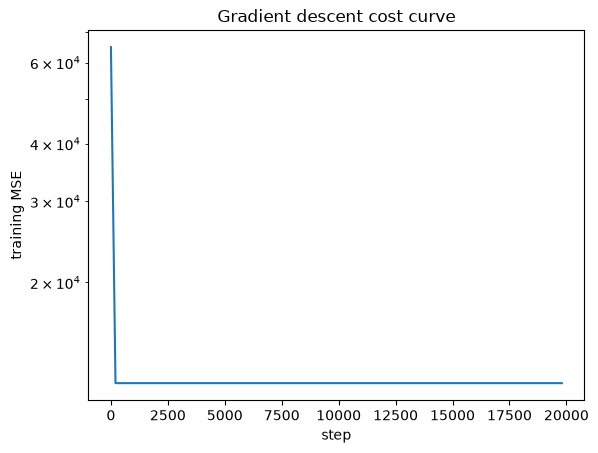

In [24]:
x = X_train["sqft"].to_numpy() / 1000
y_tr = y_train.to_numpy()

w, b = 0.0, 0.0
alpha = 0.02
history = []
for step in range(20_000):
    y_hat = w * x + b
    error = y_hat - y_tr
    dw = 2 * np.mean(error * x)
    db = 2 * np.mean(error)
    w -= alpha * dw
    b -= alpha * db
    if step % 200 == 0:
        history.append(mse(y_tr, y_hat))

print(f"GD:  price = {w:.2f} * (sqft/1000) {b:+.2f}")
print(f"  -> Rs. {w:.1f}M per extra 1,000 sq ft")

plt.plot(np.arange(len(history)) * 200, history)
plt.xlabel("step"); plt.ylabel("training MSE"); plt.yscale("log")
plt.title("Gradient descent cost curve")
plt.show()

### 4.2 Simple LR with scikit-learn (OLS) (slide 11)

Ordinary Least Squares solves for the same line in one step. GD and OLS should agree.

In [25]:
from sklearn.linear_model import LinearRegression

slr = LinearRegression().fit(X_train[["sqft"]], y_train)
print(f"OLS: price = {slr.coef_[0]:.4f} * sqft {slr.intercept_:+.2f}")
print(f"GD : price = {w / 1000:.4f} * sqft {b:+.2f}")

OLS: price = 0.0540 * sqft -6.39
GD : price = 0.0540 * sqft -6.39


### 4.3 See the Line and Its Residuals (slide 11)

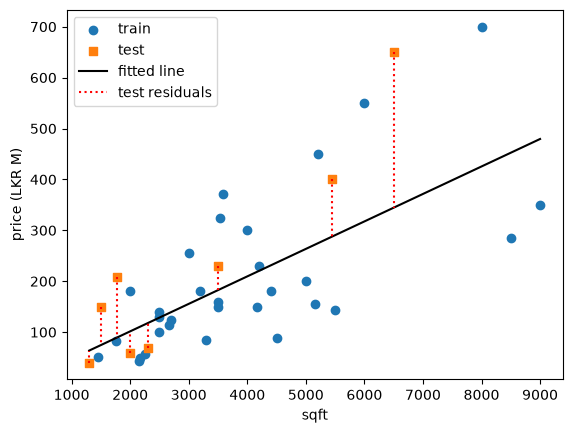

In [26]:
xs = np.linspace(X["sqft"].min(), X["sqft"].max(), 100)
plt.scatter(X_train["sqft"], y_train, label="train")
plt.scatter(X_test["sqft"], y_test, marker="s", label="test")
plt.plot(xs, slr.predict(pd.DataFrame({"sqft": xs})), color="black", label="fitted line")

pred_test = slr.predict(X_test[["sqft"]])
plt.vlines(X_test["sqft"], y_test, pred_test, colors="red", linestyles="dotted", label="test residuals")
plt.xlabel("sqft"); plt.ylabel("price (LKR M)"); plt.legend()
plt.show()

### 4.4 Metrics from Scratch (slide 12)

$$\text{MAE} = \frac{1}{n}\sum|y-\hat{y}| \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum(y-\hat{y})^2} \qquad R^2 = 1 - \frac{\sum(y-\hat{y})^2}{\sum(y-\bar{y})^2}$$

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def mae(y, p):  return np.mean(np.abs(y - p))
def rmse(y, p): return np.sqrt(np.mean((y - p) ** 2))
def r2(y, p):   return 1 - np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2)

yt = y_test.to_numpy()
print(f"MAE : {mae(yt, pred_test):7.2f}   sklearn {mean_absolute_error(yt, pred_test):7.2f}")
print(f"RMSE: {rmse(yt, pred_test):7.2f}   sklearn {np.sqrt(mean_squared_error(yt, pred_test)):7.2f}")
print(f"R2  : {r2(yt, pred_test):7.3f}   sklearn {r2_score(yt, pred_test):7.3f}")

MAE :   96.97   sklearn   96.97
RMSE:  128.89   sklearn  128.89
R2  :   0.562   sklearn   0.562


### 4.5 Multiple LR: All 4 Features (slide 12)

$\hat{y} = w_1\,\text{sqft} + w_2\,\text{perches} + w_3\,\text{bedrooms} + w_4\,\text{dist\_fort\_km} + b$

In [28]:
mlr = LinearRegression().fit(X_train, y_train)

terms = " ".join(f"{c:+.3f}·{f}" for c, f in zip(mlr.coef_, FEATURES))
print(f"price = {terms} {mlr.intercept_:+.2f}")
pd.Series(mlr.coef_, index=FEATURES).round(3)

price = +0.034·sqft +6.606·perches -2.594·bedrooms -25.540·dist_fort_km +145.51


sqft             0.034
perches          6.606
bedrooms        -2.594
dist_fort_km   -25.540
dtype: float64

### 4.6 Compare the Two Models (slide 13)

In [29]:
def scores(y, p):
    return {"MAE (Rs. M)": mae(y, p), "RMSE (Rs. M)": rmse(y, p), "R2": r2(y, p)}

pred_slr = slr.predict(X_test[["sqft"]])
pred_mlr = mlr.predict(X_test)
results = pd.DataFrame({"Simple LR (sqft)": scores(yt, pred_slr),
                        "Multiple LR (4 features)": scores(yt, pred_mlr)}).T.round(3)
results

,MAE (Rs. M),RMSE (Rs. M),R2
Simple LR (sqft),96.972,128.888,0.562
Multiple LR (4 features),67.909,103.403,0.718


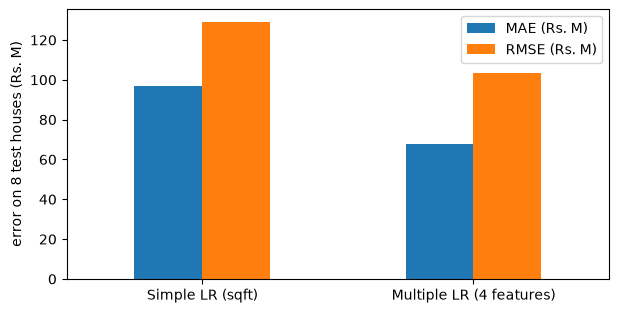

In [30]:
results[["MAE (Rs. M)", "RMSE (Rs. M)"]].plot.bar(rot=0, figsize=(7, 3.5))
plt.ylabel("error on 8 test houses (Rs. M)")
plt.show()

**Only 8 test houses.** One lucky or unlucky split can swing these scores a lot. 5-fold cross-validation gives each house a turn in the test set:

In [31]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, cols in [("Simple LR", ["sqft"]), ("Multiple LR", FEATURES)]:
    cv = cross_val_score(LinearRegression(), X[cols], y, cv=kf, scoring="r2")
    print(f"{name:<12} R2 per fold: {cv.round(2)}  mean {cv.mean():.2f}")

Simple LR    R2 per fold: [ 0.56 -0.24  0.58 -0.04  0.39]  mean 0.25
Multiple LR  R2 per fold: [ 0.72  0.5   0.72  0.18 -0.32]  mean 0.36


Across folds the scores swing widely, and some folds go negative: a negative ^2$ means that fold's predictions were worse than just guessing the average price. Both mean scores sit well below the single 80/20 split. Multiple LR still wins on average, but with 39 houses no single test score should be read as final.

### 4.7 Reading the Coefficients (slide 13)

- **`dist_fort_km`** is strongly negative: each km further from Fort lowers the price by tens of millions, holding size fixed.
- **`bedrooms`** comes out *negative*. More bedrooms don't make a house cheaper. Bedrooms move with `sqft` (**multicollinearity**), so the model splits their credit oddly. Coefficients show what the model learned from this data, not cause and effect.
- With 31 training rows, every weight is noisy. Week 04's regularization tames this.

In [32]:
df_clean[["sqft", "bedrooms"]].corr().iloc[0, 1].round(2)

np.float64(0.63)

### 4.8 Extra: The Normal Equation

OLS has a closed form: $\mathbf{w} = (X^\top X)^{-1} X^\top \mathbf{y}$. Add a column of 1s so the bias is learned too (Week 02 §2.7: inverses).

In [33]:
Xb = np.c_[np.ones(len(X_train)), X_train.to_numpy()]
theta = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y_train.to_numpy()
print("normal eq :", theta.round(3))
print("sklearn   :", np.r_[mlr.intercept_, mlr.coef_].round(3))

normal eq : [145.514   0.034   6.606  -2.594 -25.54 ]
sklearn   : [145.514   0.034   6.606  -2.594 -25.54 ]


## Part 05 — Live Predictions, Streamlit & Wrap-Up

### 5.1 Predicting the Unseen Test Houses (slide 14)

In [34]:
showcase = df_clean.loc[X_test.index, ["location"] + FEATURES + [TARGET]].copy()
showcase["simple_pred"] = pred_slr.round(1)
showcase["multiple_pred"] = pred_mlr.round(1)
showcase["multiple_error"] = (showcase["multiple_pred"] - showcase[TARGET]).round(1)
showcase.sort_values(TARGET)

,location,sqft,perches,bedrooms,dist_fort_km,price_m_lkr,simple_pred,multiple_pred,multiple_error
6,Nugegoda (Udahamulla),1300.0,8.00,4.0,10.5,40.0,63.8,-35.6,-75.6
4,Nugegoda (Stanley Thilakarathna),2000.0,11.00,4.0,9.8,59.0,101.6,26.1,-32.9
13,Pita Kotte (Two Storey),2300.0,10.00,4.0,8.8,68.0,117.8,55.3,-12.7
26,Colombo 5 (Police Park Ave),1500.0,9.00,3.0,5.0,150.0,74.6,120.9,-29.1
27,Colombo 5 (Edmonton Rd),1775.0,15.42,6.0,5.5,208.0,89.4,152.2,-55.8
30,Colombo 7 (Col 7 Residential),3500.0,12.00,4.0,3.5,230.0,182.5,245.0,15.0
33,Colombo 7 (Bullers Lane),5441.0,17.84,5.0,3.6,400.0,287.3,345.0,-55.0
36,Colombo 7 (Alexandra Place 1),6500.0,17.30,5.0,3.4,650.0,344.5,382.9,-267.1


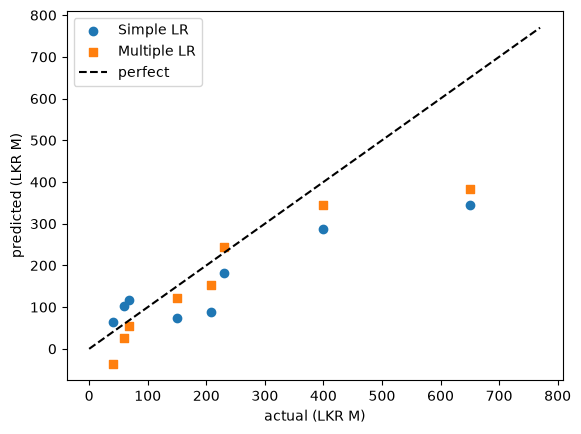

In [35]:
lim = [0, y.max() * 1.1]
plt.scatter(yt, pred_slr, label="Simple LR")
plt.scatter(yt, pred_mlr, marker="s", label="Multiple LR")
plt.plot(lim, lim, "k--", label="perfect")
plt.xlabel("actual (LKR M)"); plt.ylabel("predicted (LKR M)"); plt.legend()
plt.show()

### 5.2 `predict_house()` on a New Listing (slide 15)

In [36]:
def predict_house(sqft, perches, bedrooms, dist_fort_km, model=mlr):
    row = pd.DataFrame([[sqft, perches, bedrooms, dist_fort_km]], columns=FEATURES)
    return model.predict(row)[0]

print(f"Dehiwala 3,000 sqft, 10p, 4BR, 8 km : Rs. {predict_house(3000, 10, 4, 8.0):.1f}M")
print(f"Colombo 5 3,000 sqft, 10p, 4BR, 5 km: Rs. {predict_house(3000, 10, 4, 5.0):.1f}M")

Dehiwala 3,000 sqft, 10p, 4BR, 8 km : Rs. 99.7M
Colombo 5 3,000 sqft, 10p, 4BR, 5 km: Rs. 176.4M


**Extrapolation trap.** Our data stops at 10.5 km from Fort. Ask about a house in Kottawa (~18 km):

In [37]:
print(f"Training dist range: {X['dist_fort_km'].min()}–{X['dist_fort_km'].max()} km")
print(f"Kottawa 2,500 sqft, 10p, 4BR, 18 km: Rs. {predict_house(2500, 10, 4, 18.0):.1f}M  <- negative!")

Training dist range: 3.2–10.5 km
Kottawa 2,500 sqft, 10p, 4BR, 18 km: Rs. -172.8M  <- negative!


A straight line keeps going forever. Only trust predictions inside the range the model was trained on.

### 5.3 Save the Model (slide 15)

In [38]:
import joblib

joblib.dump({"model": mlr, "features": FEATURES}, "sl_house_model.pkl")
loaded = joblib.load("sl_house_model.pkl")
print("reloaded prediction:", round(predict_house(3300, 12, 4, 9.4, model=loaded["model"]), 1))

reloaded prediction: 87.5


### 5.4 A Streamlit Price App (slide 15)

Run locally with `streamlit run app.py`. In Colab, run it behind a tunnel such as `npx localtunnel --port 8501`.

In [39]:
%%writefile app.py
import joblib
import pandas as pd
import streamlit as st

bundle = joblib.load("sl_house_model.pkl")
model, features = bundle["model"], bundle["features"]

st.title("Sri Lankan House Price Predictor")
sqft = st.slider("Floor area (sq ft)", 1000, 9000, 3000, step=100)
perches = st.slider("Land (perches)", 6.0, 25.0, 12.0, step=0.5)
bedrooms = st.slider("Bedrooms", 2, 8, 4)
dist = st.slider("Distance to Colombo Fort (km)", 3.0, 10.5, 6.0, step=0.1)

row = pd.DataFrame([[sqft, perches, bedrooms, dist]], columns=features)
st.metric("Estimated asking price", f"Rs. {model.predict(row)[0]:,.1f} M")
st.caption("Trained on 31 LankaPropertyWeb listings. Valid only within the slider ranges.")

Writing app.py


## Wrap-Up (slide 16)

| Stage | Key idea |
|---|---|
| Scrape | HTML cards → text columns with `requests` + BeautifulSoup |
| Clean | regex parsing, drop non-house ads, median-impute gaps, handle outliers |
| Split | 80/20, test houses stay unseen |
| Train | Simple LR (1 feature) vs Multiple LR (4 features), fitted by GD and OLS |
| Evaluate | MAE, RMSE, $R^2$, plus cross-validation for small data |

**The big idea:** more relevant features usually cut the error, but with 31 houses the weights are noisy and the line is only valid inside the data's range.

**Next week:** Overfitting and Ridge/Lasso regularization, keeping noisy weights like `bedrooms` in check.

## Practice

1. Add a `price_per_perch` column. Which location has the most expensive land?
2. Train Multiple LR without `bedrooms`. Does the test MAE go up or down? Why?
3. Retrain with `np.log(price_m_lkr)` as the target and compare $R^2$. (Remember to `np.exp` the predictions.)
4. Change `random_state` to 0, 1 and 2. How much do the test scores move?
5. In 4.1, try `alpha = 0.1`. What happens to the cost curve?
6. Find 5 new listings on ikman.lk, add them to the CSV and retrain.